# Лабораторна робота №2: Апроксимація функцій мережею прямого поширення (PyTorch)

## Мета роботи
Реалізувати мережу прямого поширення засобами **Python та PyTorch** для апроксимації функції $f(x) = x^2$. Дослідити вплив архітектури (кількість шарів і нейронів), кількості епох, функцій активації та оптимізаторів, порівняти навчену функцію з еталоном і розширити мережу на функцію $f(x) = x^3 + 2x$.

## Короткі теоретичні відомості
Мережа прямого поширення є композицією лінійних шарів і нелінійних активацій: $h_l = \phi(W_l h_{l-1} + b_l)$, $\hat{y} = W_L h_{L-1} + b_L$. За теоремою про універсальну апроксимацію мережа з одним прихованим шаром і нелінійною активацією здатна наблизити будь-яку неперервну функцію на компакті з довільною точністю. Для регресії мінімізується середньоквадратична похибка, яка також є метрикою змагання:
$$\text{MSE} = \frac{1}{N} \sum_{i=1}^N (y_i - \hat{y}_i)^2$$

## 0. Налаштування середовища
Якщо папки `data` немає, завантажуємо дані змагання через Kaggle CLI. У Google Colab токен береться із Secrets (`KAGGLE_API_TOKEN`). `SUBMIT = True` вмикає відправку `submission.csv` на Kaggle наприкінці.

In [1]:
import os
import sys

COMPETITION = "lab-2-feedforward-neural-network"
SUBMIT = False  # set True to upload submission.csv to Kaggle at the end

if "google.colab" in sys.modules:
    from google.colab import userdata

    os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")
    %pip install -q -U kaggle
!test -d data || (kaggle competitions download -c {COMPETITION} -p data && unzip -q data/{COMPETITION}.zip -d data)

## 1. Завантаження даних
`train.csv` містить точки $y = x^2$, які розділимо на навчальну (80%) та валідаційну (20%) частини.

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

DATA_DIR = Path("data")

train = torch.tensor(np.loadtxt(DATA_DIR / "train.csv", delimiter=",", skiprows=1), dtype=torch.float32)
test = torch.tensor(np.loadtxt(DATA_DIR / "test.csv", delimiter=",", skiprows=1), dtype=torch.float32)
x_all, y_all, x_test = train[:, 1:2], train[:, 2:3], test[:, 1:2]

perm = torch.randperm(len(x_all), generator=torch.Generator().manual_seed(42))
va, tr = perm[: len(perm) // 5], perm[len(perm) // 5 :]
x_tr, y_tr, x_va, y_va = x_all[tr], y_all[tr], x_all[va], y_all[va]

print(f"Train: {len(x_tr)} точок, x у [{x_all.min():.1f}, {x_all.max():.1f}]")
print(f"Validation: {len(x_va)} точок")
print(f"Test: {len(x_test)} точок, x у [{x_test.min():.1f}, {x_test.max():.1f}]")

Train: 320 точок, x у [-2.0, 2.0]
Validation: 80 точок
Test: 100 точок, x у [-3.0, 3.0]


## 2. Реалізація мережі та циклу навчання

In [3]:
ACTIVATIONS = {"sigmoid": nn.Sigmoid, "tanh": nn.Tanh, "relu": nn.ReLU}
OPTIMIZERS = {"SGD": torch.optim.SGD, "RMSprop": torch.optim.RMSprop, "Adam": torch.optim.Adam}


def make_ffn(hidden: tuple[int, ...], activation: str) -> nn.Sequential:
    layers, d_in = [], 1
    for d_out in hidden:
        layers += [nn.Linear(d_in, d_out), ACTIVATIONS[activation]()]
        d_in = d_out
    return nn.Sequential(*layers, nn.Linear(d_in, 1))


def train_model(y_tr, y_va, hidden=(64, 64), activation="relu", optimizer="Adam", epochs=500):
    torch.manual_seed(42)
    model = make_ffn(hidden, activation)
    opt = OPTIMIZERS[optimizer](model.parameters(), lr=1e-2)
    val_mse = []
    for _ in range(epochs):
        opt.zero_grad()
        F.mse_loss(model(x_tr), y_tr).backward()
        opt.step()
        with torch.no_grad():
            val_mse.append(F.mse_loss(model(x_va), y_va).item())
    return model, val_mse

## 3. Архітектура та кількість епох
Переберемо мережі з 1..4 прихованими шарами по 8, 32 або 64 нейрони (ReLU, Adam) і простежимо валідаційний MSE за епохами.

In [4]:
depths, widths = (1, 2, 3, 4), (8, 32, 64)
arch = {(d, w): train_model(y_tr, y_va, hidden=(w,) * d) for d in depths for w in widths}

epochs_shown = (1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 50, 100, 500)
print("Валідаційний MSE за епохами (64 нейрони у шарі):")
print("Шари | " + " | ".join(f"{e:>6}" for e in epochs_shown))
for d in depths:
    print(f"{d:>4} | " + " | ".join(f"{arch[d, 64][1][e - 1]:6.3f}" for e in epochs_shown))

print("\nВалідаційний MSE після 500 епох:")
print("Шари | " + " | ".join(f"{w:>3} нейр." for w in widths))
for d in depths:
    print(f"{d:>4} | " + " | ".join(f"{arch[d, w][1][-1]:9.2e}" for w in widths))

Валідаційний MSE за епохами (64 нейрони у шарі):
Шари |      1 |      2 |      3 |      4 |      5 |      6 |      7 |      8 |      9 |     10 |     50 |    100 |    500
   1 |  1.689 |  1.309 |  1.013 |  0.801 |  0.667 |  0.604 |  0.600 |  0.637 |  0.692 |  0.746 |  0.020 |  0.005 |  0.000
   2 |  1.495 |  0.864 |  0.656 |  0.895 |  1.105 |  0.991 |  0.715 |  0.464 |  0.316 |  0.259 |  0.005 |  0.001 |  0.000
   3 |  2.012 |  1.320 |  0.789 |  1.203 |  1.435 |  0.952 |  0.548 |  0.418 |  0.415 |  0.404 |  0.008 |  0.002 |  0.000
   4 |  2.444 |  1.715 |  0.820 |  1.674 |  1.077 |  0.495 |  0.437 |  0.457 |  0.384 |  0.251 |  0.006 |  0.001 |  0.000

Валідаційний MSE після 500 епох:
Шари |   8 нейр. |  32 нейр. |  64 нейр.
   1 |  5.37e-03 |  7.15e-04 |  9.37e-05
   2 |  3.61e-03 |  7.24e-05 |  2.21e-05
   3 |  9.89e-04 |  1.37e-05 |  1.83e-05
   4 |  2.39e-04 |  2.46e-05 |  1.06e-05


## 4. Функції активації та оптимізатори
Для мережі 2x64 порівняємо активації `sigmoid`, `tanh`, `relu` (оптимізатор Adam) та оптимізатори `SGD`, `RMSprop`, `Adam` (активація ReLU, однаковий крок навчання $10^{-2}$).

In [5]:
acts = {name: train_model(y_tr, y_va, activation=name) for name in ACTIVATIONS}
opts = {name: train_model(y_tr, y_va, optimizer=name) for name in OPTIMIZERS}

for title, runs in (("Активація", acts), ("Оптимізатор", opts)):
    print(f"{title:<12} | MSE еп. 10 | MSE еп. 500")
    for name, (_, val_mse) in runs.items():
        print(f"{name:<12} | {val_mse[9]:10.4f} | {val_mse[-1]:11.2e}")
    print()

Активація    | MSE еп. 10 | MSE еп. 500
sigmoid      |     1.2582 |    7.68e-04
tanh         |     0.9873 |    5.50e-05
relu         |     0.2589 |    2.21e-05

Оптимізатор  | MSE еп. 10 | MSE еп. 500
SGD          |     0.8858 |    4.36e-03
RMSprop      |     0.5449 |    1.74e-02
Adam         |     0.2589 |    2.21e-05



## 5. Складніша функція $f(x) = x^3 + 2x$
Навчимо ту саму мережу 2x64 (ReLU, Adam) на значеннях $x^3 + 2x$ для тих самих точок $x$.

In [6]:
def cubic(x: torch.Tensor) -> torch.Tensor:
    return x**3 + 2 * x


cubic_model, cubic_mse = train_model(cubic(x_tr), cubic(x_va))
print(f"Валідаційний MSE для x^3 + 2x: {cubic_mse[-1]:.2e}")

Валідаційний MSE для x^3 + 2x: 3.62e-04


## 6. Візуалізація результатів

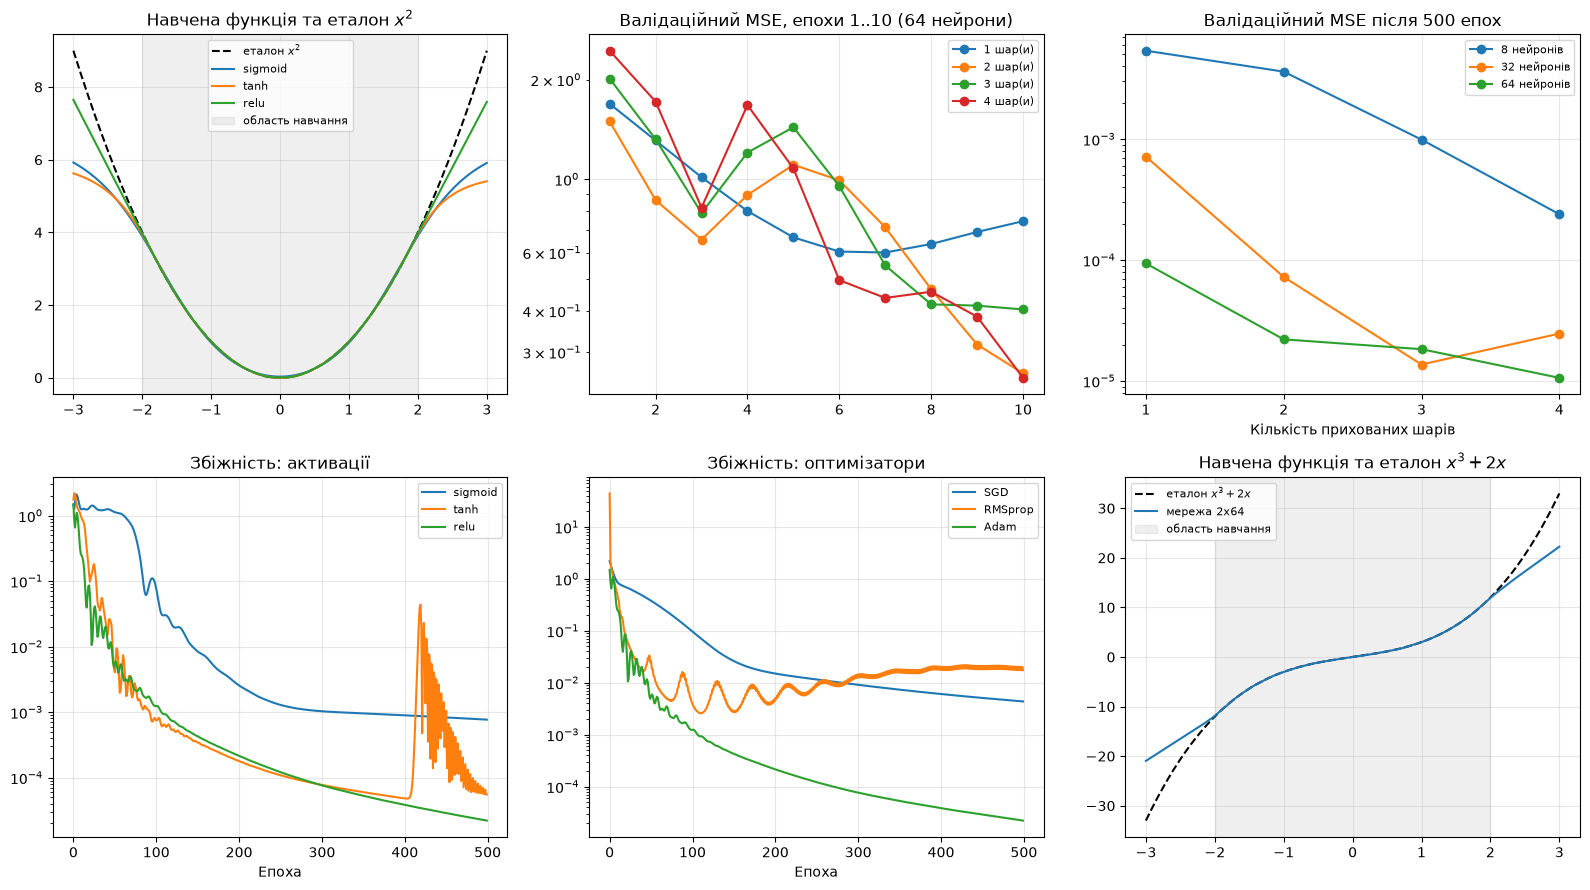

In [7]:
x_grid = torch.linspace(-3, 3, 300).unsqueeze(1)


def predict(model: nn.Module) -> np.ndarray:
    with torch.no_grad():
        return model(x_grid).squeeze(1).numpy()


fig, axes = plt.subplots(2, 3, figsize=(16, 9))

ax = axes[0, 0]
ax.plot(x_grid, x_grid**2, "k--", label="еталон $x^2$")
for name, (model, _) in acts.items():
    ax.plot(x_grid, predict(model), label=name)
ax.axvspan(-2, 2, color="gray", alpha=0.12, label="область навчання")
ax.set_title("Навчена функція та еталон $x^2$")

ax = axes[0, 1]
for d in depths:
    ax.plot(range(1, 11), arch[d, 64][1][:10], marker="o", label=f"{d} шар(и)")
ax.set_title("Валідаційний MSE, епохи 1..10 (64 нейрони)")

ax = axes[0, 2]
for w in widths:
    ax.plot(depths, [arch[d, w][1][-1] for d in depths], marker="o", label=f"{w} нейронів")
ax.set_xticks(depths)
ax.set_xlabel("Кількість прихованих шарів")
ax.set_title("Валідаційний MSE після 500 епох")

for ax, runs, title in ((axes[1, 0], acts, "Збіжність: активації"), (axes[1, 1], opts, "Збіжність: оптимізатори")):
    for name, (_, val_mse) in runs.items():
        ax.plot(val_mse, label=name)
    ax.set_xlabel("Епоха")
    ax.set_title(title)

ax = axes[1, 2]
ax.plot(x_grid, cubic(x_grid), "k--", label="еталон $x^3 + 2x$")
ax.plot(x_grid, predict(cubic_model), label="мережа 2x64")
ax.axvspan(-2, 2, color="gray", alpha=0.12, label="область навчання")
ax.set_title("Навчена функція та еталон $x^3 + 2x$")

for ax in axes.flat:
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
for ax in (axes[0, 1], axes[0, 2], axes[1, 0], axes[1, 1]):
    ax.set_yscale("log")
plt.tight_layout()
plt.show()

## 7. Формування `submission.csv`
Для прогнозу використаємо архітектуру з найменшим валідаційним MSE.

In [8]:
best = min(arch, key=lambda k: arch[k][1][-1])
with torch.no_grad():
    y_pred = arch[best][0](x_test)
print(f"Найкраща архітектура: {best[0]} шар(и) по {best[1]} нейронів")
print(f"MSE на тестових точках відносно x^2: {F.mse_loss(y_pred, x_test**2).item():.4f}")

np.savetxt(
    "submission.csv",
    np.column_stack([test[:, 0].numpy(), y_pred.squeeze(1).numpy()]),
    delimiter=",", header="id,y_pred", comments="", fmt=["%d", "%.6f"],
)

Найкраща архітектура: 4 шар(и) по 64 нейронів
MSE на тестових точках відносно x^2: 0.1607


Відправка на Kaggle (при `SUBMIT = True`) та перелік відправок:

In [9]:
import time

if SUBMIT:
    !kaggle competitions submit -c {COMPETITION} -f submission.csv -m "Lab 2 submission"
    # scoring is asynchronous: poll the newest submission for up to ~5 minutes
    for _ in range(30):
        latest = !kaggle competitions submissions -c {COMPETITION} --csv
        if "PENDING" not in "".join(latest):
            break
        time.sleep(10)
!kaggle competitions submissions -c {COMPETITION}

  0%|                                              | 0.00/1.17k [00:00<?, ?B/s]

100%|█████████████████████████████████████| 1.17k/1.17k [00:00<00:00, 2.36kB/s]


Submission ref: 58938981


99 submissions remaining today.
Successfully submitted to Lab 2: Feedforward neural network

     ref  fileName        date                        description       status                     publicScore  privateScore  
--------  --------------  --------------------------  ----------------  -------------------------  -----------  ------------  
58938981  submission.csv  2026-11-26 09:21:11.283000  Lab 2 submission  SubmissionStatus.COMPLETE  0.16617      0.15524       


## Висновки
1. Глибші та ширші мережі точніше наближають $x^2$: валідаційний MSE після 500 епох зменшується з `5.37e-3` (1 шар, 8 нейронів) до `1.06e-5` (4 шари по 64 нейрони). За перші 10 епох жодна архітектура не встигає навчитися (MSE 0.25..0.75), після 50 епох MSE становить 0.005..0.02.
2. Серед активацій найкращий результат дає `relu` (`2.21e-5`), далі `tanh` (`5.50e-5`) і `sigmoid` (`7.68e-4`), яка збігається найповільніше. Поза областю навчання $[-2, 2]$ `sigmoid` і `tanh` насичуються, а `relu` продовжує функцію лінійно.
3. За однакового кроку $10^{-2}$ `Adam` досягає MSE `2.21e-5`, `SGD` збігається значно повільніше (`4.36e-3`), а `RMSprop` осцилює і зупиняється на `1.74e-2`.
4. Та сама мережа 2x64 наближає $x^3 + 2x$ на $[-2, 2]$ з валідаційним MSE `3.62e-4`, але поза цим відрізком також екстраполює лінійно.
5. Тестові точки лежать на $[-3, 3]$, тому похибка найкращої мережі (4 шари по 64 нейрони) на них становить `0.1607` і майже повністю зумовлена екстраполяцією.